In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [73]:
from pathlib import Path

import pandas as pd

In [7]:
import duckdb
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt

In [8]:
#PLT 한글 깨짐 방지코드
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [44]:
data_path = "C:\\AI Equipment Failure Prediction\\lectures\\week9\\01_실습_20_261109_7\\01_실습\\01-01_철강_공정_개관_설비태그.csv"
df = pd.read_csv(data_path)

In [45]:
df.columns.tolist()

['tag', 'unit', 'sample_value', 'note']

In [53]:
# TODO 1: tag를 '-' 기준으로 분해하고 아래 컬럼을 추가하세요.
# plant, process_code, equipment_code, unit_no, measurement_code

df['tag'].head()

0    PL1-SNT-FAN-01-VIB
1    PL1-SNT-FAN-01-CUR
2    PL1-SNT-CNV-02-SPD
3    PL1-CKO-PMP-01-PRS
4    PL1-CKO-FUR-01-TMP
Name: tag, dtype: str

In [54]:
# tag를 '-' 기준으로 나눠서 5개 컬럼으로 펼침 (expand=True → DataFrame으로 반환)
df[['plant', 'process_code', 'equipment_code', 'unit_no', 'measurement_code']] = df['tag'].str.split('-', expand=True)


In [55]:
df.columns.to_list()

['tag',
 'unit',
 'sample_value',
 'note',
 'plant',
 'process_code',
 'equipment_code',
 'unit_no',
 'measurement_code']

In [56]:
df['process_code'].head()

0    SNT
1    SNT
2    SNT
3    CKO
4    CKO
Name: process_code, dtype: str

In [58]:
# TODO 2: process_code를 한글 공정명으로 매핑하세요.
#process_names = process_names = {
#    "SNT": "소결",      # Sintering
#    "CKO": "코크스",    # Coke Oven
#    "BF":  "고로",      # Blast Furnace
#    "BOF": "전로",      # Basic Oxygen Furnace
#    "CCM": "연주",      # Continuous Casting Machine
#    "HSM": "열연",      # Hot Strip Mill
#    "CRM": "냉연",      # Cold Rolling Mill
#    "UTL": "유틸리티",  # Utility}


In [61]:
process_names = {
    "SNT": "소결",      # Sintering
    "CKO": "코크스",    # Coke Oven
    "BF":  "고로",      # Blast Furnace
    "BOF": "전로",      # Basic Oxygen Furnace
    "CCM": "연주",      # Continuous Casting Machine
    "HSM": "열연",      # Hot Strip Mill
    "CRM": "냉연",      # Cold Rolling Mill
    "UTL": "유틸리티",  # Utility
}

# 미등록 코드는 NaN → "미등록"으로 채움 (TODO 4 조건)
df["process_name"] = df["process_code"].map(process_names)


In [62]:
df.head()

,tag,unit,sample_value,note,plant,process_code,equipment_code,unit_no,measurement_code,process_name
0,PL1-SNT-FAN-01-VIB,mm/s,2.8,소결 주배풍기 진동,PL1,SNT,FAN,01,VIB,소결
1,PL1-SNT-FAN-01-CUR,A,412.5,소결 주배풍기 전류,PL1,SNT,FAN,01,CUR,소결
2,PL1-SNT-CNV-02-SPD,m/s,1.6,소결광 이송 컨베이어 속도,PL1,SNT,CNV,02,SPD,소결
3,PL1-CKO-PMP-01-PRS,bar,6.2,코크스로 냉각수 펌프 토출압,PL1,CKO,PMP,01,PRS,코크스
4,PL1-CKO-FUR-01-TMP,degC,1042.0,코크스로 연소실 온도,PL1,CKO,FUR,01,TMP,코크스


In [75]:
# TODO 3: 공정 단계(stage)를 분류하세요.
# 소결·코크스·고로: 상공정
# 전로·연주·열연·냉연: 하공정
# 유틸리티: 유틸리티

df["stage"] = df["process_name"].map({
    "소결": "상공정",
    "코크스": "상공정",
    "고로": "상공정",
    "전로": "상공정",
    "연주": "상공정",
    "열연": "하공정",
    "냉연": "하공정",
    "유틸리티": "유틸리티"
})


In [76]:
df.head()

,tag,unit,sample_value,note,plant,process_code,equipment_code,unit_no,measurement_code,process_name,stage
0,PL1-SNT-FAN-01-VIB,mm/s,2.8,소결 주배풍기 진동,PL1,SNT,FAN,01,VIB,소결,상공정
1,PL1-SNT-FAN-01-CUR,A,412.5,소결 주배풍기 전류,PL1,SNT,FAN,01,CUR,소결,상공정
2,PL1-SNT-CNV-02-SPD,m/s,1.6,소결광 이송 컨베이어 속도,PL1,SNT,CNV,02,SPD,소결,상공정
3,PL1-CKO-PMP-01-PRS,bar,6.2,코크스로 냉각수 펌프 토출압,PL1,CKO,PMP,01,PRS,코크스,상공정
4,PL1-CKO-FUR-01-TMP,degC,1042.0,코크스로 연소실 온도,PL1,CKO,FUR,01,TMP,코크스,상공정


In [78]:
df["process_name"].value_counts()

process_name
고로      4
열연      4
소결      3
연주      3
냉연      3
유틸리티    3
코크스     2
전로      2
Name: count, dtype: int64

In [79]:
df["stage"].value_counts()

stage
상공정     14
하공정      7
유틸리티     3
Name: count, dtype: int64

In [ ]:
# TODO 4: 공정별 태그 수와 계측 항목별 태그 수를 집계하세요.
# 미등록 코드는 "미등록"으로 표시하고, 태그 구조가 5개 마디인지 확인하세요.

In [41]:
df["process_name"].value_counts()

process_name
고로      4
열연      4
소결      3
연주      3
냉연      3
유틸리티    3
코크스     2
전로      2
Name: count, dtype: int64

In [42]:
df["stage"].value_counts()

stage
하공정     12
상공정      9
유틸리티     3
Name: count, dtype: int64

In [ ]:

# 미등록 코드는 "미등록"으로 표시하고, 태그 구조가 5개 마디인지 확인하세요.

In [ ]:
#실습2 제선 운전 데이터에서 변화 구간을 찾아 판정하세요.

In [95]:
data_path = "C:\\AI Equipment Failure Prediction\\lectures\\week9\\01_실습_20_261109_7\\01_실습\\01-02_제선_12시간_실습데이터.csv"
df1 = pd.read_csv(data_path)

In [96]:
df1.head()

,timestamp,blast_flow_nm3min,blast_pressure_kpa,top_pressure_kpa,blower_vib_mms,hot_blast_temp_c
0,2026-10-12 00:00:00,5188.2,211.9,204.2,3.39,1196.3
1,2026-10-12 00:01:00,5196.7,208.2,204.3,3.40,1185.5
2,2026-10-12 00:02:00,5207.7,209.6,205.4,3.24,1182.4
3,2026-10-12 00:03:00,5208.3,212.4,205.0,3.38,1183.5
4,2026-10-12 00:04:00,5202.1,209.3,205.5,3.29,1190.3


In [97]:
df1.columns.to_list()

['timestamp',
 'blast_flow_nm3min',
 'blast_pressure_kpa',
 'top_pressure_kpa',
 'blower_vib_mms',
 'hot_blast_temp_c']

cols = [
    # 측정 시각 (시간 순서 기준, datetime으로 변환해서 사용)
    'timestamp',
    # 송풍량: 고로에 불어 넣는 바람의 양 (단위: Nm³/min, 표준상태 기준 분당 부피)
    'blast_flow_nm3min',
    # 송풍 압력: 고로로 보내는 바람의 압력 (단위: kPa)
    'blast_pressure_kpa',
    # 노정 압력: 고로 꼭대기(노정)의 가스 압력 (단위: kPa)
    'top_pressure_kpa',
    # 송풍기 진동: 송풍기(블로워)의 진동 크기 (단위: mm/s, 진동 속도)
    'blower_vib_mms',
    # 열풍 온도: 열풍로에서 데워 고로로 보내는 바람의 온도 (단위: °C)
    'hot_blast_temp_c'
]


In [98]:
# TODO 1: 송풍량과 송풍압의 30분 이동평균을 추가해 변화 구간을 찾아보세요.


In [99]:
df1['timestamp'] = pd.to_datetime(df1['timestamp'])

In [100]:
df1['timestamp'].info()

<class 'pandas.Series'>
RangeIndex: 720 entries, 0 to 719
Series name: timestamp
Non-Null Count  Dtype         
--------------  -----         
720 non-null    datetime64[us]
dtypes: datetime64[us](1)
memory usage: 5.8 KB


In [101]:
df1.set_index('timestamp', inplace=True)
df1.head()

,blast_flow_nm3min,blast_pressure_kpa,top_pressure_kpa,blower_vib_mms,hot_blast_temp_c
timestamp,,,,,
2026-10-12 00:00:00,5188.2,211.9,204.2,3.39,1196.3
2026-10-12 00:01:00,5196.7,208.2,204.3,3.40,1185.5
2026-10-12 00:02:00,5207.7,209.6,205.4,3.24,1182.4
2026-10-12 00:03:00,5208.3,212.4,205.0,3.38,1183.5
2026-10-12 00:04:00,5202.1,209.3,205.5,3.29,1190.3


In [82]:
cols=['blast_flow_nm3min', 'blast_pressure_kpa']

In [89]:
df1['blast_flow_nm3min'].head()

timestamp
2026-10-12 00:00:00    5188.2
2026-10-12 00:01:00    5196.7
2026-10-12 00:02:00    5207.7
2026-10-12 00:03:00    5208.3
2026-10-12 00:04:00    5202.1
Name: blast_flow_nm3min, dtype: float64

In [102]:
df1['blast_flow_nm30min']=df1['blast_flow_nm3min'].rolling('30min').mean()
df1.head()

,blast_flow_nm3min,blast_pressure_kpa,top_pressure_kpa,blower_vib_mms,hot_blast_temp_c,blast_flow_nm30min
timestamp,,,,,,
2026-10-12 00:00:00,5188.2,211.9,204.2,3.39,1196.3,5188.200000
2026-10-12 00:01:00,5196.7,208.2,204.3,3.40,1185.5,5192.450000
2026-10-12 00:02:00,5207.7,209.6,205.4,3.24,1182.4,5197.533333
2026-10-12 00:03:00,5208.3,212.4,205.0,3.38,1183.5,5200.225000
2026-10-12 00:04:00,5202.1,209.3,205.5,3.29,1190.3,5200.600000


In [103]:
df1['blast_pressure_kpa_30min']=df1['blast_pressure_kpa'].rolling('30min').mean()
df1.head()

,blast_flow_nm3min,blast_pressure_kpa,top_pressure_kpa,blower_vib_mms,hot_blast_temp_c,blast_flow_nm30min,blast_pressure_kpa_30min
timestamp,,,,,,,
2026-10-12 00:00:00,5188.2,211.9,204.2,3.39,1196.3,5188.200000,211.900
2026-10-12 00:01:00,5196.7,208.2,204.3,3.40,1185.5,5192.450000,210.050
2026-10-12 00:02:00,5207.7,209.6,205.4,3.24,1182.4,5197.533333,209.900
2026-10-12 00:03:00,5208.3,212.4,205.0,3.38,1183.5,5200.225000,210.525
2026-10-12 00:04:00,5202.1,209.3,205.5,3.29,1190.3,5200.600000,210.280


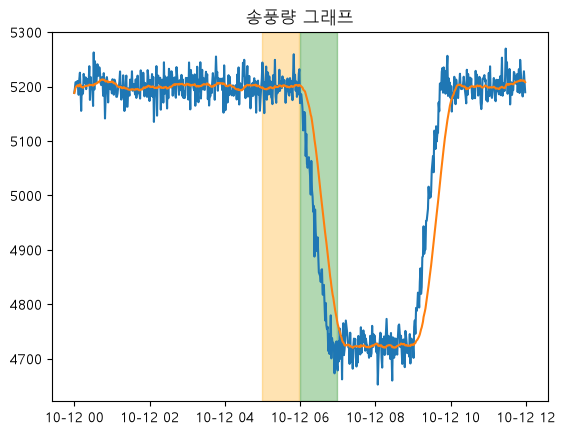

In [164]:
plt.plot(df1['blast_flow_nm3min'])
plt.plot(df1['blast_flow_nm30min'])
plt.title('송풍량 그래프')
plt.axvspan(pd.Timestamp("2026-10-12 05:00"), pd.Timestamp("2026-10-12 05:59"),
            color="orange", alpha=0.3)
plt.axvspan(pd.Timestamp("2026-10-12 06:00"), pd.Timestamp("2026-10-12 06:59"),
            color="green", alpha=0.3)
plt.show()

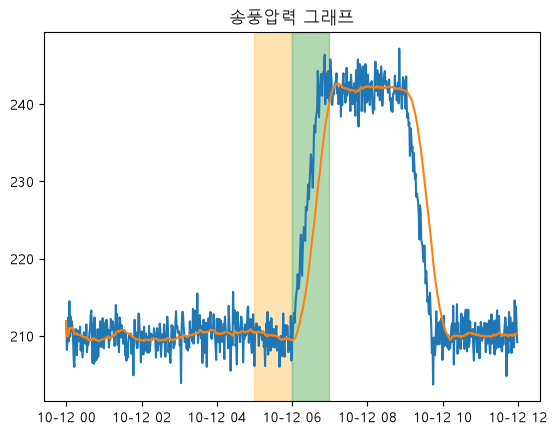

In [165]:
plt.plot(df1['blast_pressure_kpa'])
plt.plot(df1['blast_pressure_kpa_30min'])
plt.title('송풍압력 그래프')
plt.axvspan(pd.Timestamp("2026-10-12 05:00"), pd.Timestamp("2026-10-12 05:59"),
            color="orange", alpha=0.3)
plt.axvspan(pd.Timestamp("2026-10-12 06:00"), pd.Timestamp("2026-10-12 06:59"),
            color="green", alpha=0.3)
plt.show()

In [106]:
# TODO 2: 노정압의 30분 이동 표준편차를 계산하고 흔들림이 커진 시각을 찾으세요.

In [115]:
df1['top_pressure_kpa30std']=df1['top_pressure_kpa'].rolling('30min').std()
df1.head()

,blast_flow_nm3min,blast_pressure_kpa,top_pressure_kpa,blower_vib_mms,hot_blast_temp_c,blast_flow_nm30min,blast_pressure_kpa_30min,top_pressure_kpa30std
timestamp,,,,,,,,
2026-10-12 00:00:00,5188.2,211.9,204.2,3.39,1196.3,5188.200000,211.900,NaN
2026-10-12 00:01:00,5196.7,208.2,204.3,3.40,1185.5,5192.450000,210.050,0.070711
2026-10-12 00:02:00,5207.7,209.6,205.4,3.24,1182.4,5197.533333,209.900,0.665833
2026-10-12 00:03:00,5208.3,212.4,205.0,3.38,1183.5,5200.225000,210.525,0.573730
2026-10-12 00:04:00,5202.1,209.3,205.5,3.29,1190.3,5200.600000,210.280,0.605805


In [117]:
df1['top_pressure_kpa30std'].head()

timestamp
2026-10-12 00:00:00         NaN
2026-10-12 00:01:00    0.070711
2026-10-12 00:02:00    0.665833
2026-10-12 00:03:00    0.573730
2026-10-12 00:04:00    0.605805
Name: top_pressure_kpa30std, dtype: float64

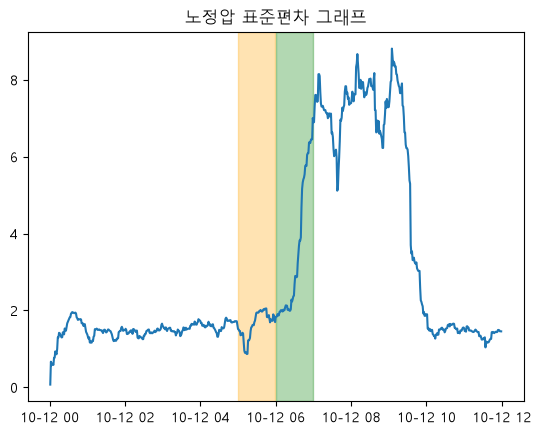

In [171]:
plt.plot(df1['top_pressure_kpa30std'])
plt.title('노정압 표준편차 그래프')
plt.axvspan(pd.Timestamp("2026-10-12 05:00"), pd.Timestamp("2026-10-12 05:59"),
            color="orange", alpha=0.3)
plt.axvspan(pd.Timestamp("2026-10-12 06:00"), pd.Timestamp("2026-10-12 06:59"),
            color="green", alpha=0.3)

plt.show()

In [173]:
print(df1['top_pressure_kpa30std'].max())
print(df1['top_pressure_kpa30std'].idxmax())

8.813179785470995
2026-10-12 09:05:00


In [120]:
# TODO 3: 송풍기 진동이 같은 구간에서 어떻게 변했는지 확인하세요.

In [159]:
#    'blower_vib_mms', ????????????


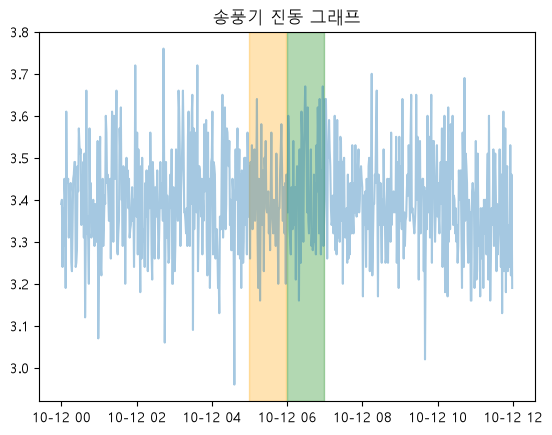

In [170]:
plt.plot(df1['blower_vib_mms'],alpha = 0.4) #?
plt.title('송풍기 진동 그래프')
plt.axvspan(pd.Timestamp("2026-10-12 05:00"), pd.Timestamp("2026-10-12 05:59"),
            color="orange", alpha=0.3)
plt.axvspan(pd.Timestamp("2026-10-12 06:00"), pd.Timestamp("2026-10-12 06:59"),
            color="green", alpha=0.3)
plt.show()


In [157]:
# TODO 3 풀이
before = df1.loc["2026-10-12 05:00":"2026-10-12 05:59", "blower_vib_mms"]
after  = df1.loc["2026-10-12 06:00":"2026-10-12 06:59", "blower_vib_mms"]
print(before.mean().round(2), after.mean().round(2), (after.mean() - before.mean()).round(2))


3.4 3.42 0.02


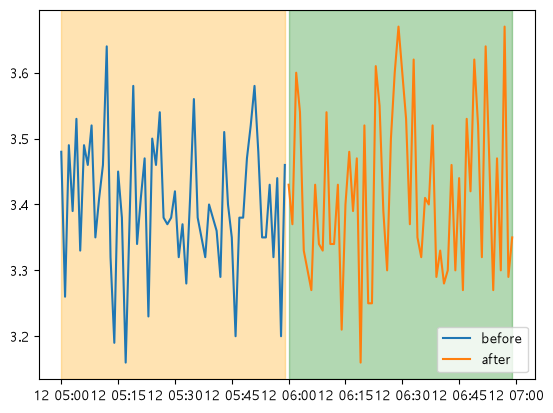

In [156]:
plt.plot(before, label="before")
plt.plot(after, label="after")
plt.axvspan(pd.Timestamp("2026-10-12 05:00"), pd.Timestamp("2026-10-12 05:59"),
            color="orange", alpha=0.3)
plt.axvspan(pd.Timestamp("2026-10-12 06:00"), pd.Timestamp("2026-10-12 06:59"),
            color="green", alpha=0.3)
plt.legend()
plt.show()


In [160]:
# TODO 4: 시작 시각, 변화 방향, 진동 근거를 포함해 판정문을 작성하세요.


In [ ]:
# TODO 4: 
#   (2026-10-12 06:00 )부터 송풍량은 ( 감소 ), 송풍압은 ( 증가 )했고,
#    노정압 흔들림은 ( 시각 )에 최대였다.
#    같은 구간 송풍기 진동은 ( 3.4 )→( 3.42 ) mm/s로 ( 대체로 유지 )했다."

In [ ]:
# TODO 5: 신호 -> 현상 -> 원인 후보 -> 확인 자료 순서로 추적 경로를 작성하세요.
#   신호     : 06시부터 송풍량 감소, 숭풍압력 증가, 진동은 유지
#   현상     : 바람을 세게 밀어도 덜 들어감. 노 안의 가스 흐름이 불안정함
#   원인 후보 : 
#   확인 자료 : 조업 일지,